# Stage 2 — LSTM Bike-Sharing Forecasting

**Task:** Predict the next day's seven variables from the previous seven daily observations. Grid search compares one-layer (Vanilla) and two-layer (Stacked) LSTMs. Select the LSTM configuration using validation performance; evaluate test performance only after the team's finalist choice is fixed.

Load `day.csv`

In [ ]:
import pandas as pd

df = pd.read_csv('day.csv')
print('Loaded day.csv:', df.shape)
display(df.head(3))

Loaded day.csv: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349


Date indexing and preprocessing

In [ ]:
df = df.rename(columns={'dteday': 'date'})
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date') #make date the new index for this to be a true time series
df.head()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
date,,,,,,,,,,,,,,,
2011-01-01,1,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
2011-01-02,2,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2011-01-03,3,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
2011-01-04,4,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
2011-01-05,5,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# first 70% of time series is training - can be used to create scaler object
train_limit = int(len(df) * 0.70)

# Apply a log transform to the cnt, casual, registered variables to remove non-stationarity
log_cnt = np.log(df['cnt'])
log_casual = np.log(df['casual'])
log_registered = np.log(df['registered'])

# Initialize Scalers
scaler_cnt = MinMaxScaler()
scaler_casual = MinMaxScaler()
scaler_registered = MinMaxScaler()

# Fit scalers on training portion only, then transform entire series
scaler_cnt.fit(log_cnt.values[:train_limit].reshape(-1, 1))
scaled_log_cnt = scaler_cnt.transform(log_cnt.values.reshape(-1, 1))

scaler_casual.fit(log_casual.values[:train_limit].reshape(-1, 1))
scaled_log_casual = scaler_casual.transform(log_casual.values.reshape(-1, 1))

scaler_registered.fit(log_registered.values[:train_limit].reshape(-1, 1))
scaled_log_registered = scaler_registered.transform(log_registered.values.reshape(-1, 1))

In [ ]:
# Initialize Scalers for temp and atemp
scaler_temp = MinMaxScaler()
scaler_atemp = MinMaxScaler()

# Fit on training portion only, then transform
scaler_temp.fit(df['temp'].values[:train_limit].reshape(-1, 1))
scaled_temp = scaler_temp.transform(df['temp'].values.reshape(-1, 1))

scaler_atemp.fit(df['atemp'].values[:train_limit].reshape(-1, 1))
scaled_atemp = scaler_atemp.transform(df['atemp'].values.reshape(-1, 1))

In [ ]:
# Initialize Scalers for windspeed and hum
scaler_windspeed = MinMaxScaler()
scaler_hum = MinMaxScaler()

# Fit on training portion only, then transform
scaler_windspeed.fit(df['windspeed'].values[:train_limit].reshape(-1, 1))
scaled_windspeed = scaler_windspeed.transform(df['windspeed'].values.reshape(-1, 1))

scaler_hum.fit(df['hum'].values[:train_limit].reshape(-1, 1))
scaled_hum = scaler_hum.transform(df['hum'].values.reshape(-1, 1))

##Multivariate sliding windows and chronological splits


In [ ]:
import numpy as np

# 1. Combine our 7 parallel scaled features into a single 2D array of shape (731, 7)
# Note: ensuring all features are reshaped properly to 1D before column_stack
multivariate_data = np.column_stack([
    scaled_log_cnt.flatten(),
    scaled_log_casual.flatten(),
    scaled_log_registered.flatten(),
    scaled_temp.flatten(),
    scaled_atemp.flatten(),
    scaled_windspeed.flatten(),
    scaled_hum.flatten()
])

print("Combined multivariate data shape:", multivariate_data.shape)

Combined multivariate data shape: (731, 7)


In [ ]:
# 2. Define a function to split our parallel sequences into sliding window samples predicting all variables
def split_multivariate_sequences(sequences, lookback, horizon=1):
    X, y = [], []
    for i in range(len(sequences)):
        # find the end of this pattern
        end_ix = i + lookback
        out_end_ix = end_ix + horizon - 1
        # check if we are beyond the dataset
        if out_end_ix >= len(sequences):
            break
        # gather input (past history) and output (future values for all 7 variables)
        seq_x, seq_y = sequences[i:end_ix, :], sequences[end_ix:out_end_ix + 1, :]
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

# Define parameters
L = 7  # Lookback window (7 days of history)
h = 1  # Horizon (predicting 1 day into the future)

# 3. Create the dataset
X, y = split_multivariate_sequences(multivariate_data, lookback=L, horizon=h)

print("X shape (samples, lookback, features):", X.shape)
print("y shape (samples, horizon, features):", y.shape)

X shape (samples, lookback, features): (724, 7, 7)
y shape (samples, horizon, features): (724, 1, 7)


In [ ]:
# Calculate the split indices
total_samples = len(X)
train_end = int(total_samples * 0.70)       # 70% for Training
val_end = int(total_samples * 0.85)         # 15% for Validation, remaining 15% for Test

# Split inputs (X)
X_train, X_val, X_test = X[:train_end], X[train_end:val_end], X[val_end:]

# Split targets (y)
y_train, y_val, y_test = y[:train_end], y[train_end:val_end], y[val_end:]

print(f"Total sliding window samples: {total_samples}")
print(f"Train set shape:      X={X_train.shape}, y={y_train.shape}")
print(f"Validation set shape: X={X_val.shape}, y={y_val.shape}")
print(f"Test set shape:       X={X_test.shape}, y={y_test.shape}")

Total sliding window samples: 724
Train set shape:      X=(506, 7, 7), y=(506, 1, 7)
Validation set shape: X=(109, 7, 7), y=(109, 1, 7)
Test set shape:       X=(109, 7, 7), y=(109, 1, 7)


---
# LSTM

## 1. LSTM inputs and architecture

We use the existing three-dimensional windows `(samples, 7 days, 7 features)` directly. This is a multivariate, one-step-ahead sequence-to-vector forecasting problem: one past sequence predicts seven next-day variables. Unlike the MLP, we do **not** flatten the LSTM inputs. We flatten only the target shape from `(samples, 1, 7)` to `(samples, 7)`.

The LSTM maintains a cell state and uses input, forget, and output gates to control information across the time steps. We'll compare a **Vanilla LSTM** (one recurrent layer) with a **Stacked LSTM** (two recurrent layers, with `return_sequences=True` on the first). A dropout layer helps regularize the model; the final linear Dense layer predicts continuous values.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import json
import joblib
from pathlib import Path
from itertools import product
from time import perf_counter
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display, Markdown

# The same seven features and feature order as the main notebook
FEATURES = ['cnt', 'casual', 'registered',
            'temp', 'atemp', 'windspeed', 'hum']
LOG_FEATURES = ['cnt', 'casual', 'registered']

# Use original 3D windows; do not flatten the inputs
X_train_lstm = np.asarray(X_train, dtype=np.float32)
X_val_lstm = np.asarray(X_val, dtype=np.float32)
X_test_lstm = np.asarray(X_test, dtype=np.float32)

# Flatten only the one-day, seven-variable targets
Y_train_lstm = y_train.reshape(len(y_train), -1).astype(np.float32)
Y_val_lstm = y_val.reshape(len(y_val), -1).astype(np.float32)
Y_test_lstm = y_test.reshape(len(y_test), -1).astype(np.float32)

# Exact scalers already fitted in the shared preprocessing
scalers_lstm = {
    'cnt': scaler_cnt,
    'casual': scaler_casual,
    'registered': scaler_registered,
    'temp': scaler_temp,
    'atemp': scaler_atemp,
    'windspeed': scaler_windspeed,
    'hum': scaler_hum,
}

def inverse_cnt_lstm(values):
    # Inverse MinMax, then inverse natural log (np.exp)
    log_counts = scaler_cnt.inverse_transform(
        np.asarray(values).reshape(-1, 1)
    )
    return np.exp(log_counts).ravel()

# Use date index already constructed in the shared pipeline
all_target_dates = df.index[L + h - 1:]
val_dates_lstm = all_target_dates[train_end:val_end]
test_dates_lstm = all_target_dates[val_end:]

# Local output folder
LSTM_DIR = Path('stage2_lstm_artifacts')
LSTM_DIR.mkdir(parents=True, exist_ok=True)

print('Train:', X_train_lstm.shape, Y_train_lstm.shape)
print('Validation:', X_val_lstm.shape, Y_val_lstm.shape)
print('Test:', X_test_lstm.shape, Y_test_lstm.shape)

assert X_train_lstm.ndim == 3 and X_train_lstm.shape[1:] == (L, len(FEATURES))
assert Y_train_lstm.shape[1] == len(FEATURES)
assert len(test_dates_lstm) == len(X_test_lstm)

Train: (506, 7, 7) (506, 7)
Validation: (109, 7, 7) (109, 7)
Test: (109, 7, 7) (109, 7)


## 2. Grid search — architecture and hyperparameters

**Search space (defined before running the trials):** Architecture ∈ {Vanilla, Stacked}; LSTM units ∈ {16, 32}; Adam learning rate ∈ {0.001, 0.0005}. This produces **8 trials**. All trials use a batch size of 32, dropout 0.2, MSE loss, MAE tracking, a 200-epoch budget, and early stopping after 25 epochs without improving validation loss.

The model's optimizer uses gradient clipping (`clipnorm=1.0`) to limit large updates. Each trial is ranked by **lowest validation MSE averaged across all seven scaled outputs**, matching the primary loss in the existing MLP. Validation rental-count MAE/RMSE are additionally reported to support cross-model comparison. The test set is not consulted during tuning.

In [ ]:
EPOCHS = 200
PATIENCE = 25
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
SEED = 42

ARCHITECTURES = ["Vanilla", "Stacked"]
UNITS_GRID = [16, 32]
LR_GRID = [0.001, 0.0005]


def build_lstm(architecture, units, learning_rate):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(L, len(FEATURES)))
    ])
    if architecture == "Vanilla":
        model.add(tf.keras.layers.LSTM(units))
    elif architecture == "Stacked":
        model.add(tf.keras.layers.LSTM(units, return_sequences=True))
        model.add(tf.keras.layers.LSTM(units))
    else:
        raise ValueError(f"Unsupported architecture: {architecture}")
    model.add(tf.keras.layers.Dropout(DROPOUT_RATE))
    model.add(tf.keras.layers.Dense(len(FEATURES), activation="linear"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="mse", metrics=["mae"]
    )
    return model

trial_rows = []
selected_val_mse = float("inf")
selected_history = None
selected_path = LSTM_DIR / "best_lstm.keras"
configs = list(product(ARCHITECTURES, UNITS_GRID, LR_GRID))

for trial_id, (architecture, units, learning_rate) in enumerate(configs, 1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    candidate = build_lstm(architecture, units, learning_rate)
    callback = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True
    )

    start = perf_counter()
    history = candidate.fit(
        X_train_lstm, Y_train_lstm,
        validation_data=(X_val_lstm, Y_val_lstm),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        shuffle=False, callbacks=[callback], verbose=0
    )
    train_seconds = perf_counter() - start

    val_mse, val_mae = candidate.evaluate(X_val_lstm, Y_val_lstm, verbose=0)
    candidate.predict(X_val_lstm, verbose=0)  # inference warm-up
    start = perf_counter()
    val_prediction = candidate.predict(X_val_lstm, verbose=0)
    val_infer_seconds = perf_counter() - start
    actual_val_cnt = inverse_cnt_lstm(Y_val_lstm[:, 0])
    pred_val_cnt = inverse_cnt_lstm(val_prediction[:, 0])
    val_cnt_mae = mean_absolute_error(actual_val_cnt, pred_val_cnt)
    val_cnt_rmse = np.sqrt(mean_squared_error(actual_val_cnt, pred_val_cnt))

    row = {
        "Trial": trial_id,
        "Architecture": architecture,
        "LSTM Units": units,
        "Learning Rate": learning_rate,
        "Batch Size": BATCH_SIZE,
        "Val MSE (scaled, all outputs)": float(val_mse),
        "Val MAE (scaled, all outputs)": float(val_mae),
        "Val cnt MAE (rentals)": float(val_cnt_mae),
        "Val cnt RMSE (rentals)": float(val_cnt_rmse),
        "Best Epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "Epochs Trained": len(history.history["loss"]),
        "Parameters": int(candidate.count_params()),
        "Training Time (s)": train_seconds,
        "Validation Inference Time (s)": val_infer_seconds
    }
    trial_rows.append(row)
    print(f"Trial {trial_id}/8: {architecture}, {units} units, lr={learning_rate} "
          f"-> validation MSE={val_mse:.6f}, cnt RMSE={val_cnt_rmse:.1f}")

    if val_mse < selected_val_mse:
        selected_val_mse = float(val_mse)
        selected_history = {key: [float(v) for v in vals]
                            for key, vals in history.history.items()}
        candidate.save(selected_path, overwrite=True)

lstm_trials = pd.DataFrame(trial_rows).sort_values(
    "Val MSE (scaled, all outputs)"
).reset_index(drop=True)
selected_row = lstm_trials.iloc[0]
lstm_model = tf.keras.models.load_model(selected_path)

display(lstm_trials)
print("\nSelected model:")
print(selected_row[["Architecture", "LSTM Units", "Learning Rate",
                    "Batch Size", "Best Epoch", "Parameters",
                    "Val MSE (scaled, all outputs)"]].to_string())
lstm_model.summary()

Trial 1/8: Vanilla, 16 units, lr=0.001 -> validation MSE=0.006971, cnt RMSE=958.7
Trial 2/8: Vanilla, 16 units, lr=0.0005 -> validation MSE=0.007093, cnt RMSE=1006.5
Trial 3/8: Vanilla, 32 units, lr=0.001 -> validation MSE=0.006487, cnt RMSE=945.3
Trial 4/8: Vanilla, 32 units, lr=0.0005 -> validation MSE=0.007130, cnt RMSE=1082.7
Trial 5/8: Stacked, 16 units, lr=0.001 -> validation MSE=0.008598, cnt RMSE=1137.5
Trial 6/8: Stacked, 16 units, lr=0.0005 -> validation MSE=0.008720, cnt RMSE=1217.0
Trial 7/8: Stacked, 32 units, lr=0.001 -> validation MSE=0.007323, cnt RMSE=1013.0
Trial 8/8: Stacked, 32 units, lr=0.0005 -> validation MSE=0.008796, cnt RMSE=1293.4


,Trial,Architecture,LSTM Units,Learning Rate,Batch Size,"Val MSE (scaled, all outputs)","Val MAE (scaled, all outputs)",Val cnt MAE (rentals),Val cnt RMSE (rentals),Best Epoch,Epochs Trained,Parameters,Training Time (s),Validation Inference Time (s)
0,3,Vanilla,32,0.0010,32,0.006487,0.060811,760.646851,945.349208,199,200,5351,42.495542,0.118366
1,1,Vanilla,16,0.0010,32,0.006971,0.063464,776.957581,958.681386,123,148,1655,34.948641,0.084212
2,2,Vanilla,16,0.0005,32,0.007093,0.063979,830.040405,1006.523317,179,200,1655,42.666511,0.130493
3,4,Vanilla,32,0.0005,32,0.007130,0.065088,936.178711,1082.722725,198,200,5351,41.703611,0.139939
4,7,Stacked,32,0.0010,32,0.007323,0.066314,844.462646,1013.048586,131,156,13671,38.123140,0.082666
5,5,Stacked,16,0.0010,32,0.008598,0.073651,987.966309,1137.454230,98,123,3767,29.752375,0.092417
6,6,Stacked,16,0.0005,32,0.008720,0.074211,1059.533691,1216.966516,179,200,3767,48.026856,0.128054
7,8,Stacked,32,0.0005,32,0.008796,0.074676,1110.698242,1293.437764,23,48,13671,13.538401,0.083351



Selected model:
Architecture                      Vanilla
LSTM Units                             32
Learning Rate                       0.001
Batch Size                             32
Best Epoch                            199
Parameters                           5351
Val MSE (scaled, all outputs)    0.006487


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,055 (62.72 KB)

 Trainable params: 5,351 (20.90 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,704 (41.82 KB)

## 3. Grid-search results and learning curves

The trials table and validation-MSE plot document the eight tested configurations. Training and validation MSE/MAE curves for the **selected** model help evaluate convergence and possible overfitting. A falling training loss accompanied by a sustained rise in validation loss suggests overfitting. The saved model restores the epoch with the lowest validation MSE.

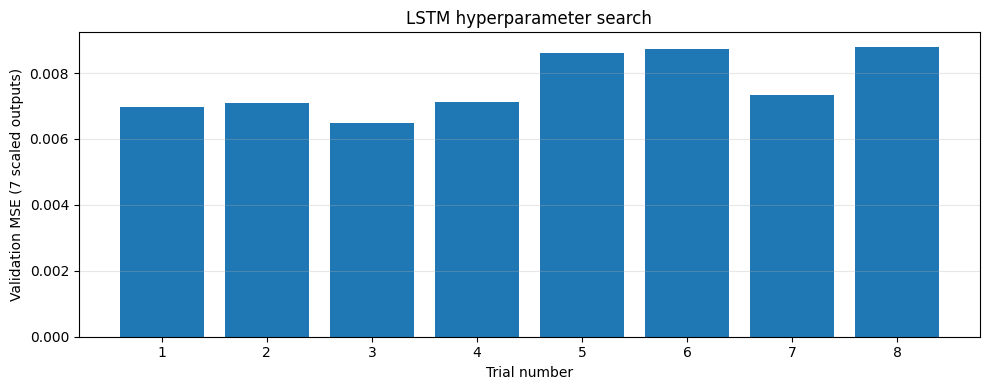

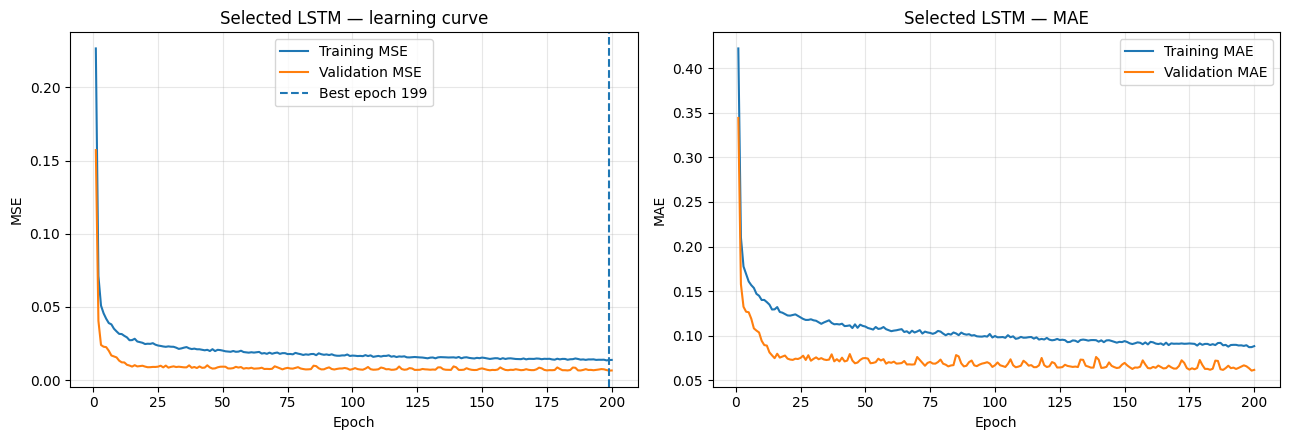

Selected model best epoch: 199
Epochs trained: 200
Training MSE at selected epoch: 0.013713
Validation MSE at selected epoch: 0.006487


In [ ]:
trial_order = lstm_trials.sort_values("Trial")
plt.figure(figsize=(10, 4))
plt.bar(trial_order["Trial"].astype(str), trial_order["Val MSE (scaled, all outputs)"])
plt.xlabel("Trial number")
plt.ylabel("Validation MSE (7 scaled outputs)")
plt.title("LSTM hyperparameter search")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_grid_search.png", dpi=180)
plt.show()

loss_train = np.asarray(selected_history["loss"])
loss_val = np.asarray(selected_history["val_loss"])
mae_train = np.asarray(selected_history["mae"])
mae_val = np.asarray(selected_history["val_mae"])
selected_best_epoch = int(np.argmin(loss_val) + 1)
xs = np.arange(1, len(loss_train) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(xs, loss_train, label="Training MSE")
axes[0].plot(xs, loss_val, label="Validation MSE")
axes[0].axvline(selected_best_epoch, linestyle="--", label=f"Best epoch {selected_best_epoch}")
axes[0].set(xlabel="Epoch", ylabel="MSE", title="Selected LSTM — learning curve")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(xs, mae_train, label="Training MAE")
axes[1].plot(xs, mae_val, label="Validation MAE")
axes[1].set(xlabel="Epoch", ylabel="MAE", title="Selected LSTM — MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_learning_curves.png", dpi=180)
plt.show()
print("Selected model best epoch:", selected_best_epoch)
print("Epochs trained:", len(loss_train))
print("Training MSE at selected epoch:", round(float(loss_train[selected_best_epoch-1]), 6))
print("Validation MSE at selected epoch:", round(float(loss_val[selected_best_epoch-1]), 6))

## 4. Validation performance and baselines

The model must be compared with the naive (last day), seasonal naive (seven days earlier), and mean baselines on **the same validation samples**. Rental-count errors are reported in original units by reversing the MinMax scaling and natural-log transform. Training/inference time and parameter counts are included for the team's Stage 2 comparison. Inference timing uses a warm-up and measures a single batched prediction call; compare timing only on the same hardware.

Validation comparison — original-scale daily bike rentals


,Model,MAE (rentals),RMSE (rentals)
0,Naive,738.320801,1059.721603
1,Seasonal Naive,853.321106,1119.552980
2,Mean,3329.241211,3439.297893
3,LSTM,760.646851,945.349208



Selected model parameters: 5351
Training time (s): 42.496
Validation inference time (s): 0.1184


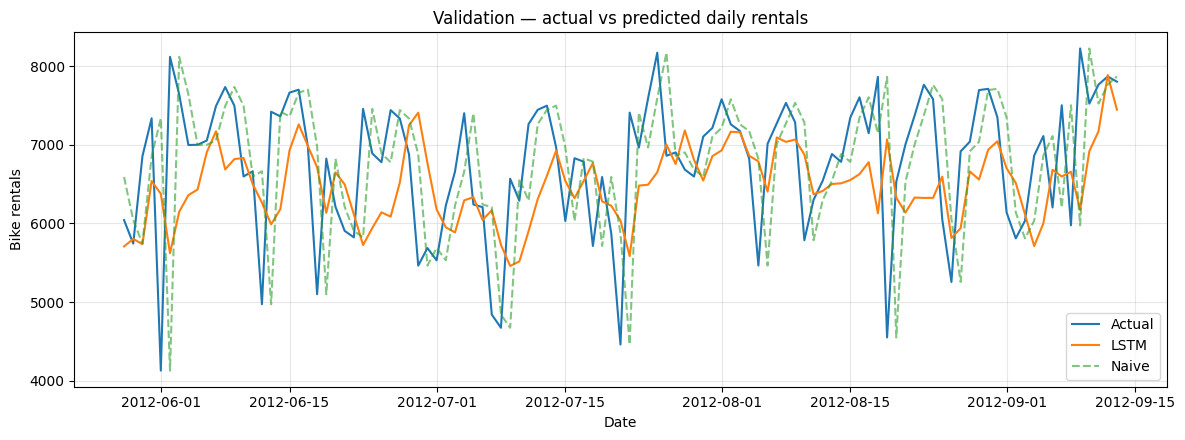

In [ ]:
def evaluate_rental_baselines(X_data, y_data, model_pred):
    actual = inverse_cnt_lstm(y_data[:, 0])
    predictions = {
        "Naive": inverse_cnt_lstm(X_data[:, -1, 0]),
        "Seasonal Naive": inverse_cnt_lstm(X_data[:, 0, 0]),
        "Mean": inverse_cnt_lstm(np.full(len(y_data), Y_train_lstm[:, 0].mean())),
        "LSTM": inverse_cnt_lstm(model_pred[:, 0])
    }
    rows = []
    for label, predicted in predictions.items():
        rows.append({
            "Model": label,
            "MAE (rentals)": mean_absolute_error(actual, predicted),
            "RMSE (rentals)": np.sqrt(mean_squared_error(actual, predicted))
        })
    return pd.DataFrame(rows), actual, predictions

validation_predictions = lstm_model.predict(X_val_lstm, verbose=0)
validation_metrics, val_actual, val_series = evaluate_rental_baselines(
    X_val_lstm, Y_val_lstm, validation_predictions
)
print("Validation comparison — original-scale daily bike rentals")
display(validation_metrics)
print("\nSelected model parameters:", lstm_model.count_params())
print("Training time (s):", round(float(selected_row["Training Time (s)"]), 3))
print("Validation inference time (s):",
      round(float(selected_row["Validation Inference Time (s)"]), 4))

plt.figure(figsize=(12, 4.5))
plt.plot(val_dates_lstm, val_actual, label="Actual")
plt.plot(val_dates_lstm, val_series["LSTM"], label="LSTM")
plt.plot(val_dates_lstm, val_series["Naive"], label="Naive", linestyle="--", alpha=0.6)
plt.title("Validation — actual vs predicted daily rentals")
plt.xlabel("Date")
plt.ylabel("Bike rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_validation_predictions.png", dpi=180)
plt.show()

## 5. Final held-out test evaluation

Use the test split to report performance **only once the team's finalist/model-selection decision has been frozen using validation results**. This cell compares the selected LSTM with the same three baselines using rental-count MAE and RMSE, records test inference time, and plots actual versus predicted rentals. No further hyperparameter tuning should use these test scores.

Test comparison — original-scale daily bike rentals


,Model,MAE (rentals),RMSE (rentals)
0,Naive,934.467957,1364.928890
1,Seasonal Naive,1380.091797,1969.521579
2,Mean,2580.057129,2893.103610
3,LSTM,1112.504761,1402.151695


7-output scaled test MSE: 0.024642
7-output scaled test MAE: 0.090437
Test inference (109 samples expected): 0.1158s
Inference per sample: 1.062 ms


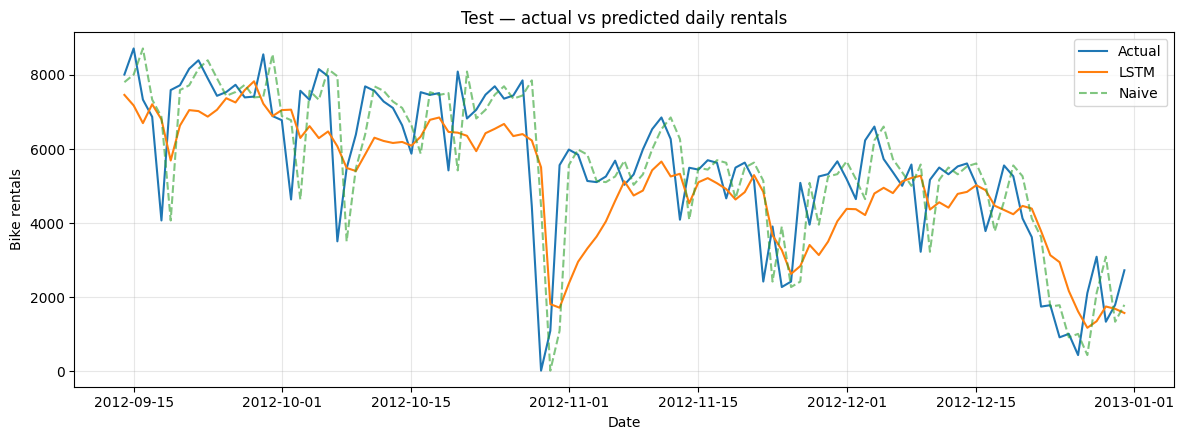

In [ ]:
test_mse_scaled, test_mae_scaled = lstm_model.evaluate(
    X_test_lstm, Y_test_lstm, verbose=0
)
lstm_model.predict(X_test_lstm, verbose=0)  # warm-up
start = perf_counter()
test_prediction = lstm_model.predict(X_test_lstm, verbose=0)
test_inference_seconds = perf_counter() - start

test_metrics, test_actual, test_series = evaluate_rental_baselines(
    X_test_lstm, Y_test_lstm, test_prediction
)
print("Test comparison — original-scale daily bike rentals")
display(test_metrics)
print(f"7-output scaled test MSE: {test_mse_scaled:.6f}")
print(f"7-output scaled test MAE: {test_mae_scaled:.6f}")
print(f"Test inference (109 samples expected): {test_inference_seconds:.4f}s")
print(f"Inference per sample: {1000 * test_inference_seconds / len(X_test_lstm):.3f} ms")

plt.figure(figsize=(12, 4.5))
plt.plot(test_dates_lstm, test_actual, label="Actual")
plt.plot(test_dates_lstm, test_series["LSTM"], label="LSTM")
plt.plot(test_dates_lstm, test_series["Naive"], label="Naive", linestyle="--", alpha=0.6)
plt.title("Test — actual vs predicted daily rentals")
plt.xlabel("Date")
plt.ylabel("Bike rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_test_predictions.png", dpi=180)
plt.show()

test_metrics.to_csv(LSTM_DIR / "lstm_test_metrics.csv", index=False)
lstm_test_row = test_metrics.set_index("Model").loc["LSTM"]
selected_config["test_cnt_mae_rentals"] = float(lstm_test_row["MAE (rentals)"])
selected_config["test_cnt_rmse_rentals"] = float(lstm_test_row["RMSE (rentals)"])
selected_config["test_mse_scaled"] = float(test_mse_scaled)
selected_config["test_mae_scaled"] = float(test_mae_scaled)
selected_config["test_inference_seconds"] = test_inference_seconds
with open(LSTM_DIR / "lstm_config.json", "w") as fp:
    json.dump(selected_config, fp, indent=2)

## LSTM Results and Overfitting Discussion

### 1. Data Preparation

The dataset was transformed into 724 multivariate sliding-window samples using a 7-day lookback and a one-day forecasting horizon. Each input contained 7 variables over 7 consecutive days, giving an input shape of (7, 7).

The data was divided chronologically into 506 training, 109 validation, and 109 testing samples. Log transformations and MinMax scaling were applied using training-fitted scalers to prevent data leakage.

Unlike the MLP, the LSTM retained the three-dimensional input structure to process observations sequentially.

### 2. LSTM Architecture and Grid Search

Grid search was implemented to compare Vanilla and Stacked LSTM architectures with different numbers of LSTM units and learning rates.

Two architectures, two unit sizes, and two learning rates were tested, resulting in **8 configurations**. The model with the lowest validation MSE across all seven scaled output variables was selected.

The best-performing configuration was:

| Hyperparameter | Selected value |
|---|---|
| Architecture | Vanilla LSTM |
| LSTM units | 32 |
| Learning rate | 0.001 |
| Batch size | 32 |
| Dropout | 0.2 |
| Optimizer | Adam |
| Loss function | MSE |
| Trainable parameters | 5,351 |
| Best epoch | 199 |
| Validation MSE | **0.006487** |

The Vanilla LSTM consisted of one LSTM layer with 32 units, followed by a dropout layer and a linear Dense output layer containing 7 neurons.

The grid-search results showed that the Vanilla LSTM configurations generally achieved lower validation errors than the Stacked LSTM configurations. The selected 32-unit Vanilla LSTM achieved the lowest validation MSE of **0.006487**.

This suggests that the simpler architecture was more effective for this dataset within the tested configurations, without requiring the additional complexity of a second LSTM layer.

### 3. Learning Curves and Overfitting Analysis

The training and validation MSE and MAE decreased rapidly during the initial epochs, indicating that the LSTM successfully learned patterns in the data.

The improvement became more gradual as training progressed, with both losses approaching relatively stable values.

The lowest validation MSE occurred at **epoch 199**, with:

- Training MSE: **0.013713**
- Validation MSE: **0.006487**

The validation MSE remained below the training MSE throughout most of training, while both curves continued decreasing without a sustained divergence.

Therefore, **there is no clear evidence of significant overfitting** in the selected LSTM.

The lower validation loss may be related to differences between the chronological training and validation periods, as well as dropout being active during training but inactive during validation.

Training completed all 200 epochs because the early stopping condition of 25 consecutive epochs without improvement was not met. The weights from epoch 199 were restored.

Although the learning curves indicate relatively stable generalization on the validation set, the best epoch occurring near the training limit suggests that additional training could be investigated.

### 4. Validation Performance and Baseline Comparison

The selected LSTM was evaluated on the validation dataset using MAE and RMSE, expressed in original daily bike rental counts.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| Naive | **738.32** | 1059.72 |
| Seasonal Naive | 853.32 | 1119.55 |
| Mean | 3329.24 | 3439.30 |
| LSTM | 760.65 | **945.35** |

The LSTM achieved the lowest validation RMSE of **945.35 rentals**, outperforming all three baselines in this metric.

However, the naive baseline achieved a slightly lower validation MAE of 738.32 rentals compared with the LSTM's 760.65 rentals.

This indicates that the LSTM reduced larger prediction errors more effectively, while the naive baseline had a slightly smaller average absolute error.

### 5. Test Evaluation and Prediction Analysis

The selected LSTM was evaluated on the held-out test dataset, producing:

| Metric | Validation | Test |
|---|---:|---:|
| MAE (rentals) | 760.65 | 1112.50 |
| RMSE (rentals) | 945.35 | 1402.15 |

The test MAE of **1112.50 rentals** indicates that the model's daily rental-count predictions differed from the actual values by approximately 1113 rentals on average.

The test RMSE of **1402.15 rentals** was slightly higher than the naive baseline's RMSE of **1364.93 rentals**.

The actual-versus-predicted graphs show that the LSTM captured general changes in daily bike rentals, but its predictions were noticeably smoother than the actual observations.

During validation, the LSTM followed the overall demand pattern but occasionally underestimated peaks and overestimated sudden decreases.

During testing, the model captured the overall downward trend toward the end of 2012. However, it struggled with abrupt fluctuations, particularly the sharp decrease and recovery in late October.

The naive baseline followed some of these sudden changes more closely, helping explain its slightly better test performance.

The increase in errors from validation to testing suggests that the later period was more difficult to predict. This does not necessarily indicate overfitting, since the chronological test period may contain different demand patterns from the validation period.

### 6. Computational Cost

The selected Vanilla LSTM contained **5,351 trainable parameters**.

The computational performance was:

| Measurement | Result |
|---|---:|
| Training time | 42.50 seconds |
| Validation inference time | 0.1184 seconds |
| Test inference time | 0.1158 seconds |
| Test samples | 109 |

The relatively small architecture provided a manageable computational cost while learning temporal relationships in the bike-sharing dataset.

These measurements can be used to compare the LSTM against the MLP, CNN, RNN, GRU, and TCN models in Stage 2.

### 7. Conclusion

Grid search selected a Vanilla LSTM with 32 units, a learning rate of 0.001, and a batch size of 32 as the best-performing configuration among eight trials.

The model achieved a minimum validation MSE of **0.006487 at epoch 199**, with learning curves showing no clear evidence of significant overfitting.

The LSTM achieved a validation RMSE of **945.35 rentals**, outperforming all three baseline models in that metric. However, its test RMSE of **1402.15 rentals** was slightly higher than the naive baseline's 1364.93 rentals.

Although the LSTM successfully captured general temporal patterns and demand trends, its smoother predictions made it less effective at reproducing sudden fluctuations.

Overall, the results demonstrate that the LSTM is a viable model for forecasting bike-sharing demand, but its additional complexity did not consistently translate into better performance than the simple naive baseline. The validation accuracy, training time, and model complexity provide evidence for the Stage 2 comparison and final model selection.